# Modelo KNN: utilidad de las parcelas de eucalipto

> Trabajo del modelo **KNN** dentro del proyecto de clasificación multiclase. Sigue la plantilla común de `docs/acuerdos.md` y los ADR del equipo.

- **Objetivo:** entrenar y evaluar un KNN comparable con los otros modelos, controlando el sobreajuste y dejando el pipeline guardado.
- **Datos:** `data/train.csv` y `data/val.csv`. **El conjunto de prueba no se lee**: se reserva para `06_conclusiones`.
- **Regla de las parcelas sin medidas:** ADR-0001. Si faltan las seis medidas (`Surv`, `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm`, `Brnch_Fm`), se responde `none` sin llamar al modelo.
- **Validación:** `StratifiedKFold` de 5 folds como esquema común y `StratifiedGroupKFold` por `Abbrev` como comprobación aparte (ADR-0002).

## 1. Carga de datos y preparación del pipeline

KNN clasifica por distancia, así que todas las variables deben estar en la misma escala: el preprocesado imputa con la mediana y estandariza las numéricas. La única categórica es `Abbrev` (el sitio), codificada con one-hot.

Se excluyen `Rep` y `PMCno` por ser identificadores y `Sp` porque tiene 25 especies con pocas parcelas cada una: en KNN añadiría 25 columnas dispersas que distorsionan las distancias. Todo el preprocesado se ajusta **solo con train** dentro del `Pipeline`.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMILLA = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** abre la caja de herramientas: trae las librerías que usaremos (pandas para las tablas, scikit-learn para el modelo, gráficos…).

**Qué encuentra:** nada que mostrar; solo deja todo listo y fija la semilla 42 para que los resultados se repitan igual.

**En cristiano:** antes de jugar, sacamos los juguetes de la caja.

In [2]:
train = pd.read_csv("data/train.csv", encoding="utf-8")
val = pd.read_csv("data/val.csv", encoding="utf-8")

ORDEN = ["none", "low", "average", "good", "best"]
conteo = pd.DataFrame({
    "train": train["Utility"].value_counts(),
    "validación": val["Utility"].value_counts(),
}).reindex(ORDEN)

print(f"Entrenamiento: {train.shape[0]} filas | Validación: {val.shape[0]} filas")
display(conteo)

Entrenamiento: 469 filas | Validación: 110 filas


,train,validación
Utility,,
none,80,27
low,75,16
average,91,19
good,150,32
best,73,16


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** lee las tablas de entrenamiento (`train`) y de validación (`val`) y cuenta cuántas parcelas hay de cada clase.

**Qué encuentra:** 469 parcelas para entrenar y 110 para validar. En ambas la clase `good` es la más numerosa y `none`, `low` y `best` las más pequeñas.

**En cristiano:** tenemos un montón de fichas para aprender y otro montón aparte para el examen; comprobamos que en los dos hay de todos los tipos.

In [3]:
MEDIDAS = ["Surv", "Vig", "Ins_res", "Stem_Fm", "Crown_Fm", "Brnch_Fm"]
NUMERICAS = ["DBH", "Ht"] + MEDIDAS
CATEGORICAS = ["Abbrev"]
VARIABLES = NUMERICAS + CATEGORICAS

X_train, y_train = train[VARIABLES], train["Utility"]
X_val, y_val = val[VARIABLES], val["Utility"]

print("Variables del modelo:", VARIABLES)
print("Excluidas:", [c for c in train.columns if c not in VARIABLES + ["Utility"]])


def crear_pipeline(**parametros_knn):
    preprocesado = ColumnTransformer([
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), NUMERICAS),
        ("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore")),
        ]), CATEGORICAS),
    ])
    return Pipeline([
        ("preprocesado", preprocesado),
        ("knn", KNeighborsClassifier(**parametros_knn)),
    ])

Variables del modelo: ['DBH', 'Ht', 'Surv', 'Vig', 'Ins_res', 'Stem_Fm', 'Crown_Fm', 'Brnch_Fm', 'Abbrev']
Excluidas: ['Rep', 'Sp', 'PMCno']


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** elige con qué datos trabaja el modelo (medidas del árbol y el sitio) y monta la "cadena de montaje" (`Pipeline`): rellena huecos, pone todo en la misma escala y le da al KNN el resultado.

**Qué encuentra:** usa 9 variables y deja fuera `Rep`, `Sp` y `PMCno`.

**En cristiano:** KNN mide "a quién te pareces" con una regla. Si una medida va en metros y otra en kilómetros, la regla se vuelve loca; por eso primero las ponemos todas en la misma unidad.

## 2. Validación cruzada y elección de hiperparámetros

Se ajustan `n_neighbors` (cuántos vecinos votan), `weights` (voto uniforme o ponderado por distancia) y `p` (distancia Manhattan o euclídea) con `GridSearchCV`, el `StratifiedKFold` común de 5 folds y F1 macro. Con `weights="distance"` el KNN se memoriza en train (cada parcela es su propio vecino a distancia 0), así que se espera un F1 de train de 1 y un gap grande; la rejilla lo deja a la vista.

Después se repite la validación agrupando por sitio con `StratifiedGroupKFold`: sirve para ver cuánto se inflan las métricas cuando el modelo ve parcelas del mismo sitio en train y validación (ADR-0002).

### Por qué esta rejilla

- **`n_neighbors` (cuántos vecinos votan):** pocos vecinos (3, 5…) dan un modelo muy sensible al ruido; muchos lo suavizan. Se prueba un rango amplio, de 3 a 101, para que el ganador no caiga en el borde de la rejilla.
- **`weights`:** `uniform` (todos los vecinos votan igual) o `distance` (los cercanos pesan más). Se prueban las dos porque `distance` suele puntuar bien en validación cruzada pero memoriza train.
- **`p`:** distancia Manhattan (1) o euclídea (2). Con variables escaladas y algunas discretas (`Vig`, `Surv`), Manhattan puede ir mejor; se deja que lo decida la validación cruzada.
- **Ampliación del rango de `k`:** una primera rejilla llegaba hasta `k = 31` y el ganador quedó justo en ese borde, así que se añadieron 41, 51, 71 y 101. Se hizo al ver también que el gap en validación quedaba cerca del límite; la elección final se sigue haciendo solo con validación cruzada sobre train, y el gap apenas cambió (de 5,5 a 5,4 puntos).
- **Regla de elección:** entre las combinaciones con gap de CV menor de 5 puntos, la de mayor F1 macro (criterio de `docs/acuerdos.md`).

In [4]:
cv_comun = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

rejilla = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 71, 101],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}
busqueda = GridSearchCV(
    crear_pipeline(),
    rejilla,
    scoring="f1_macro",
    cv=cv_comun,
    return_train_score=True,
    n_jobs=-1,
)
busqueda.fit(X_train, y_train)

tabla_cv = pd.DataFrame(busqueda.cv_results_)[[
    "param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
    "mean_test_score", "std_test_score", "mean_train_score",
]]
tabla_cv.columns = [
    "k", "pesos", "p", "F1 macro validación (media)", "desviación", "F1 macro train (media)",
]
tabla_cv["gap CV (puntos)"] = (
    tabla_cv["F1 macro train (media)"] - tabla_cv["F1 macro validación (media)"]
) * 100
display(tabla_cv.sort_values("F1 macro validación (media)", ascending=False).head(10).round(3))

print("Mejores hiperparámetros por F1:", busqueda.best_params_)
print(f"F1 macro en StratifiedKFold: {busqueda.best_score_:.3f}")

,k,pesos,p,F1 macro validación (media),desviación,F1 macro train (media),gap CV (puntos)
17,11,distance,1,0.571,0.061,1.000,42.949
15,9,distance,2,0.568,0.042,1.000,43.234
13,9,distance,1,0.568,0.059,1.000,43.237
12,9,uniform,1,0.564,0.052,0.673,10.915
16,11,uniform,1,0.562,0.039,0.648,8.559
18,11,uniform,2,0.562,0.022,0.648,8.593
19,11,distance,2,0.562,0.040,1.000,43.781
11,7,distance,2,0.562,0.041,1.000,43.805
25,21,distance,1,0.562,0.054,1.000,43.813
23,15,distance,2,0.562,0.044,1.000,43.847


Mejores hiperparámetros por F1: {'knn__n_neighbors': 11, 'knn__p': 1, 'knn__weights': 'distance'}
F1 macro en StratifiedKFold: 0.571


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** prueba muchas combinaciones de ajustes del KNN (cuántos vecinos votan, si los cercanos pesan más, qué tipo de distancia) y las puntúa con validación cruzada.

**Qué encuentra:** una tabla con las mejores combinaciones. Las que dan nota 1,0 en train y bastante menos en validación son las de `weights="distance"`: se aprenden los ejemplos de memoria (gap de unos 43 puntos).

**En cristiano:** es como probar varias formas de estudiar. Algunas "memorizan el libro" y sacan 10 en los ejercicios conocidos, pero fallan en el examen.

### Elección con el criterio de overfitting

El acuerdo del grupo elige el modelo ganador entre los que tienen un gap menor de 5 puntos. Por eso no se queda sin más con el mejor F1 de la rejilla: se miran las combinaciones cuyo gap en CV es menor de 5 puntos y, de ellas, la de mayor F1 macro. Si ninguna cumple, se usa la de mayor F1 y se explica el gap.

In [5]:
cumplen = tabla_cv[tabla_cv["gap CV (puntos)"] < 5]
print(f"Combinaciones con gap CV < 5 puntos: {len(cumplen)} de {len(tabla_cv)}")
display(cumplen.sort_values("F1 macro validación (media)", ascending=False).head(5).round(3))

candidatas = cumplen if not cumplen.empty else tabla_cv
elegida = candidatas.sort_values("F1 macro validación (media)", ascending=False).iloc[0]
PARAMETROS = {
    "n_neighbors": int(elegida["k"]),
    "weights": elegida["pesos"],
    "p": int(elegida["p"]),
}
print("Hiperparámetros elegidos:", PARAMETROS)

Combinaciones con gap CV < 5 puntos: 8 de 48


,k,pesos,p,F1 macro validación (media),desviación,F1 macro train (media),gap CV (puntos)
32,41,uniform,1,0.533,0.046,0.555,2.125
28,31,uniform,1,0.532,0.048,0.572,3.987
34,41,uniform,2,0.523,0.061,0.557,3.449
38,51,uniform,2,0.485,0.054,0.523,3.760
40,71,uniform,1,0.452,0.047,0.463,1.069


Hiperparámetros elegidos: {'n_neighbors': 41, 'weights': 'uniform', 'p': 1}


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** de todas las combinaciones, se queda solo con las que no memorizan (diferencia train–validación en CV menor de 5 puntos) y elige la mejor de ellas.

**Qué encuentra:** 8 de 48 combinaciones cumplen. Gana `k = 41`, votos iguales y distancia Manhattan.

**En cristiano:** entre los alumnos que de verdad entienden la lección, escogemos al que mejor nota saca.

In [6]:
modelo_cv = crear_pipeline(**PARAMETROS)

f1_comun = cross_val_score(
    modelo_cv, X_train, y_train, cv=cv_comun, scoring="f1_macro", n_jobs=-1
)
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
f1_grupos = cross_val_score(
    modelo_cv,
    X_train,
    y_train,
    groups=X_train["Abbrev"],
    cv=cv_grupos,
    scoring="f1_macro",
    n_jobs=-1,
)

folds = pd.DataFrame({
    "fold": range(1, 6),
    "StratifiedKFold": f1_comun,
    "StratifiedGroupKFold (por sitio)": f1_grupos,
})
display(folds.round(3))

print(f"StratifiedKFold: F1 macro = {f1_comun.mean():.3f} ± {f1_comun.std():.3f}")
print(f"StratifiedGroupKFold: F1 macro = {f1_grupos.mean():.3f} ± {f1_grupos.std():.3f}")

,fold,StratifiedKFold,StratifiedGroupKFold (por sitio)
0,1,0.546,0.579
1,2,0.581,0.461
2,3,0.580,0.433
3,4,0.487,0.657
4,5,0.473,0.333


StratifiedKFold: F1 macro = 0.533 ± 0.046
StratifiedGroupKFold: F1 macro = 0.492 ± 0.114


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** puntúa el modelo elegido de dos maneras: repartiendo las parcelas al azar (`StratifiedKFold`) y repartiéndolas por sitios, de modo que el sitio del examen no se haya visto al estudiar (`StratifiedGroupKFold`).

**Qué encuentra:** F1 macro de 0,533 ± 0,046 al azar y 0,492 ± 0,114 por sitios; con sitios la nota baja y varía mucho de un reparto a otro.

**En cristiano:** si ya conoces a los vecinos de la calle, adivinar es más fácil. Con un barrio nuevo cuesta más; esa es la nota más realista.

## 3. Métricas en validación

El modelo se reentrena con todo train. Antes de medir se aplica la regla del ADR-0001: las parcelas sin ninguna medida se predicen como `none`. Se informan las métricas sobre **toda** la validación y, aparte, solo sobre las parcelas **con medidas**, porque la regla acierta las primeras por construcción y no conviene mezclar ambas cosas.

In [7]:
modelo = crear_pipeline(**PARAMETROS).fit(X_train, y_train)


def predecir(X):
    pred = pd.Series(modelo.predict(X), index=X.index, name="predicha")
    sin_medidas = X[MEDIDAS].isna().all(axis=1)
    pred.loc[sin_medidas] = "none"
    return pred


sin_medidas_val = X_val[MEDIDAS].isna().all(axis=1)
con_medidas = ~sin_medidas_val
pred_val = predecir(X_val)
print(f"Parcelas sin medidas en validación (regla ADR-0001): {sin_medidas_val.sum()}")
print("Clases de esas parcelas:", y_val[sin_medidas_val].value_counts().to_dict())

Parcelas sin medidas en validación (regla ADR-0001): 15
Clases de esas parcelas: {'none': 15}


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** entrena el modelo con todo train y define cómo predecir: si una parcela no trae ninguna medida, se responde `none` sin preguntar al modelo (regla del ADR-0001).

**Qué encuentra:** en validación hay 15 parcelas sin medidas y todas son de verdad `none`.

**En cristiano:** si alguien llega con las manos vacías, ni miramos: sabemos que no ha traído nada.

In [8]:
def mostrar_metricas(y_true, y_pred, titulo):
    print(titulo)
    print(f"accuracy = {accuracy_score(y_true, y_pred):.3f} | "
          f"F1 macro = {f1_score(y_true, y_pred, average='macro'):.3f}")
    reporte = classification_report(
        y_true, y_pred, labels=ORDEN, output_dict=True, zero_division=0
    )
    display(pd.DataFrame(reporte).T.round(3))


mostrar_metricas(y_val, pred_val, f"Validación completa (n = {len(y_val)})")
mostrar_metricas(
    y_val[con_medidas],
    pred_val[con_medidas],
    f"Validación solo con parcelas medidas (n = {con_medidas.sum()})",
)

Validación completa (n = 110)
accuracy = 0.645 | F1 macro = 0.552


,precision,recall,f1-score,support
none,0.958,0.852,0.902,27.000
low,0.667,0.500,0.571,16.000
average,0.450,0.474,0.462,19.000
good,0.577,0.938,0.714,32.000
best,0.500,0.062,0.111,16.000
accuracy,0.645,0.645,0.645,0.645
macro avg,0.630,0.565,0.552,110.000
weighted avg,0.650,0.645,0.608,110.000


Validación solo con parcelas medidas (n = 95)
accuracy = 0.589 | F1 macro = 0.524


,precision,recall,f1-score,support
none,0.889,0.667,0.762,12.000
low,0.667,0.500,0.571,16.000
average,0.450,0.474,0.462,19.000
good,0.577,0.938,0.714,32.000
best,0.500,0.062,0.111,16.000
accuracy,0.589,0.589,0.589,0.589
macro avg,0.616,0.528,0.524,95.000
weighted avg,0.593,0.589,0.544,95.000


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** saca la nota del examen (validación): aciertos totales (accuracy) y, por clase, cuántas veces acierta cuando dice "esta es X" (precision), cuántas X encuentra (recall) y su media (F1). Una tabla con las 110 parcelas y otra solo con las 95 medidas.

**Qué encuentra:** F1 macro 0,552 (completa) y 0,524 (solo medidas). `none` y `good` van bien; `best` casi nunca se encuentra (recall 0,06).

**En cristiano:** aprueba en lo corriente, pero cuando hay que reconocer a las parcelas "mejores" casi siempre se las pierde.

predicha,none,low,average,good,best
real,,,,,
none,23,1,3,0,0
low,1,8,7,0,0
average,0,3,9,7,0
good,0,0,1,30,1
best,0,0,0,15,1


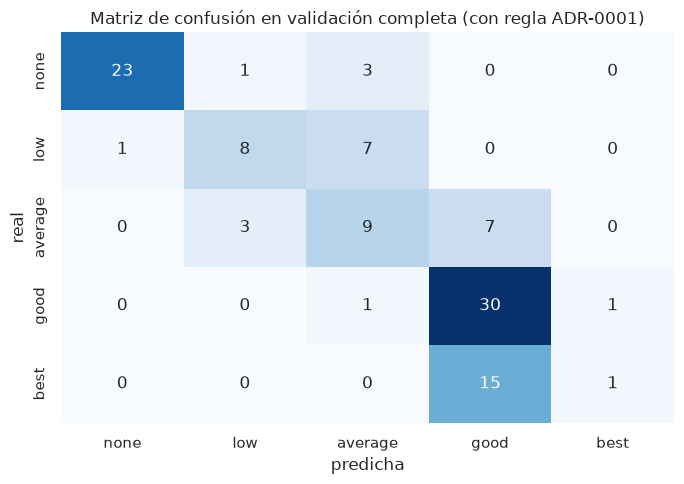

predicha,none,low,average,good,best
real,,,,,
none,8,1,3,0,0
low,1,8,7,0,0
average,0,3,9,7,0
good,0,0,1,30,1
best,0,0,0,15,1


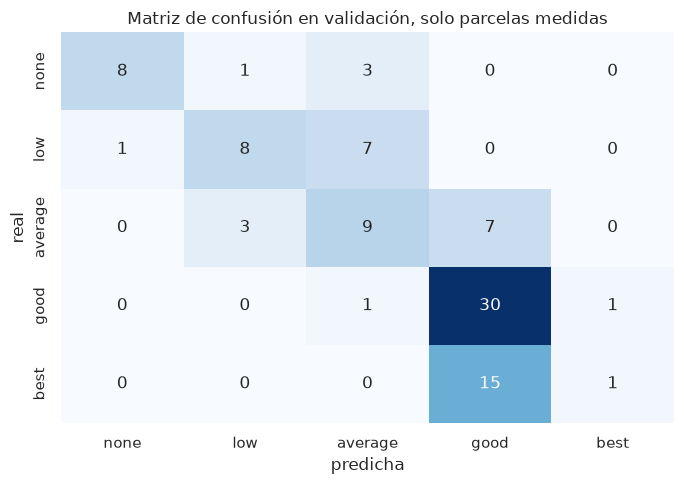

In [9]:
def dibujar_matriz(y_true, y_pred, titulo):
    matriz = pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=ORDEN), index=ORDEN, columns=ORDEN
    )
    matriz.index.name, matriz.columns.name = "real", "predicha"
    display(matriz)
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()


dibujar_matriz(y_val, pred_val, "Matriz de confusión en validación completa (con regla ADR-0001)")
dibujar_matriz(
    y_val[con_medidas], pred_val[con_medidas], "Matriz de confusión en validación, solo parcelas medidas"
)

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** dibuja la matriz de confusión: filas = lo que era de verdad, columnas = lo que dijo el modelo. La diagonal son los aciertos.

**Qué encuentra:** de las 16 parcelas `best`, 15 se marcan como `good`; `average` y `low` se mezclan con sus vecinas.

**En cristiano:** el modelo confunde "buena" con "la mejor", como cuando dudas entre un notable y un sobresaliente.

## 4. Control de overfitting

El criterio del equipo es que la diferencia de **F1 macro** entre train y validación sea menor de **5 puntos**. Para que la regla fija del ADR-0001 no infle artificialmente la validación, el gap se mide **solo con las parcelas que tienen medidas**, que son las que realmente pasa por el modelo. Train ya no contiene parcelas sin medidas, así que es comparable.

In [10]:
f1_train = f1_score(y_train, predecir(X_train), average="macro")
f1_val = f1_score(y_val, pred_val, average="macro")
f1_val_medidas = f1_score(y_val[con_medidas], pred_val[con_medidas], average="macro")
gap = (f1_train - f1_val_medidas) * 100

display(pd.DataFrame({
    "conjunto": [
        "train (modelo)",
        "validación completa (con regla)",
        "validación solo con medidas (modelo)",
    ],
    "F1 macro": [f1_train, f1_val, f1_val_medidas],
}).round(3))

print(f"Gap train - validación con medidas = {gap:.1f} puntos")
print("Cumple el criterio (< 5 puntos):", "sí" if gap < 5 else "no")
if gap < 0:
    print("El gap es negativo: no hay sobreajuste; la validación con medidas resulta "
          "algo más fácil que train en este reparto.")

,conjunto,F1 macro
0,train (modelo),0.578
1,validación completa (con regla),0.552
2,validación solo con medidas (modelo),0.524


Gap train - validación con medidas = 5.4 puntos
Cumple el criterio (< 5 puntos): no


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** compara la nota en las fichas de estudio (train) con la del examen (validación con medidas). El equipo exige que la diferencia sea menor de 5 puntos.

**Qué encuentra:** train 0,578 y validación 0,524: gap de 5,4 puntos, no cumple por 0,4. En CV era solo 2,1.

**En cristiano:** casi no ha hecho trampa, pero el margen se pasa por un pelo; el examen es pequeño (95 parcelas) y unas pocas respuestas lo mueven.

## 5. Interpretación: importancia de variables y errores

KNN no da una importancia nativa de variables, así que se usa `permutation_importance` sobre la validación **con medidas**: se mide cuánto cae el F1 macro al desordenar cada columna. Después se revisan los errores más frecuentes.

,variable,importancia,desviación
3,Vig,0.144,0.039
2,Surv,0.087,0.026
4,Ins_res,0.044,0.029
5,Stem_Fm,0.043,0.037
1,Ht,0.010,0.022
6,Crown_Fm,0.007,0.035
8,Abbrev,0.006,0.033
0,DBH,0.000,0.021
7,Brnch_Fm,-0.020,0.023


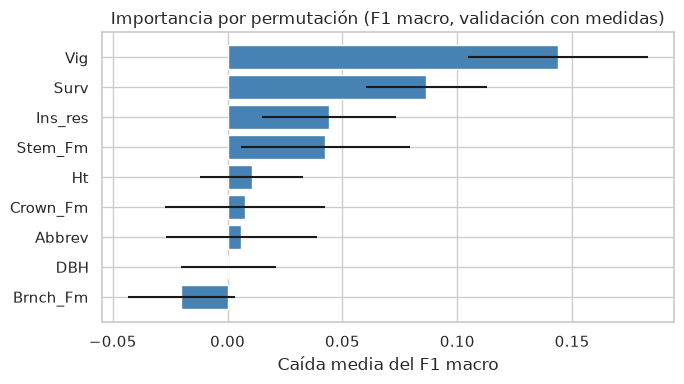

In [11]:
importancia = permutation_importance(
    modelo,
    X_val[con_medidas],
    y_val[con_medidas],
    scoring="f1_macro",
    n_repeats=10,
    random_state=SEMILLA,
    n_jobs=-1,
)

tabla_importancia = pd.DataFrame({
    "variable": X_val.columns,
    "importancia": importancia.importances_mean,
    "desviación": importancia.importances_std,
}).sort_values("importancia", ascending=False)
display(tabla_importancia.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(
    tabla_importancia["variable"][::-1],
    tabla_importancia["importancia"][::-1],
    xerr=tabla_importancia["desviación"][::-1],
    color="steelblue",
)
ax.set(
    title="Importancia por permutación (F1 macro, validación con medidas)",
    xlabel="Caída media del F1 macro",
    ylabel="",
)
plt.tight_layout()
plt.show()

### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** estropea una columna cada vez (la baraja) y mira cuánto empeora el modelo. Cuanto más empeora, más importante era.

**Qué encuentra:** `Vig` (0,14) y `Surv` (0,09) son las que más importan; el resto casi no cuenta (`Brnch_Fm` sale negativa: ruido).

**En cristiano:** para saber si el vigor del árbol importa, se lo tapamos al modelo y vemos que se pierde mucho. Con otras columnas ni se nota.

In [12]:
analisis = val.assign(predicha=pred_val)
analisis["error"] = analisis["Utility"] != analisis["predicha"]
errores = analisis[analisis["error"]]

print(f"Errores: {len(errores)} de {len(analisis)} ({len(errores) / len(analisis):.1%})")

display(
    errores.groupby(["Utility", "predicha"]).size().sort_values(ascending=False)
    .rename("n").to_frame()
)

por_clase = analisis.groupby("Utility", observed=True).agg(
    n=("error", "size"), errores=("error", "sum")
)
por_clase["tasa de error"] = (por_clase["errores"] / por_clase["n"]).round(3)
display(por_clase.reindex(ORDEN))

display(
    errores[["Abbrev", "Sp", "Vig", "Surv", "Ht", "DBH", "Utility", "predicha"]]
    .sort_values(["Utility", "predicha"])
    .head(20)
)

Errores: 39 de 110 (35.5%)


n
Utility predicha    
best    good      15
average good       7
low     average    7
none    average    3
average low        3
good    best       1
        average    1
low     none       1
none    low        1

,n,errores,tasa de error
Utility,,,
none,27,4,0.148
low,16,8,0.500
average,19,10,0.526
good,32,2,0.062
best,16,15,0.938


,Abbrev,Sp,Vig,Surv,Ht,DBH,Utility,predicha
23,Paw,nd,3.0,20.0,13.55,20.11,average,good
39,Puk,nd,3.0,100.0,7.84,16.30,average,good
50,WSh,re,3.8,25.0,8.84,22.34,average,good
65,WSp,ob,3.5,63.0,10.53,18.88,average,good
90,Lon,ov,3.0,100.0,5.57,14.53,average,good
108,WSp,fa,3.0,25.0,14.60,41.51,average,good
109,K83,fa,3.0,13.0,13.29,16.25,average,good
3,K81,si,3.0,25.0,4.27,3.56,average,low
30,K81a,ov,2.5,45.0,5.65,7.89,average,low
53,K81,br,3.0,88.0,4.11,4.62,average,low


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** lista los fallos: qué clase real se confundió con cuál, cuánto falla cada clase y ejemplos concretos.

**Qué encuentra:** 39 errores de 110 (35,5 %). El más repetido es `best` → `good` (15 veces); `best` falla el 94 % y `good` solo el 6 %.

**En cristiano:** el modelo se hace el "seguro" y dice `good` cuando duda, que es la respuesta más común; por eso acierta mucho `good` y pierde `best`.

### Observaciones de los errores

- La clase `best` casi no se acierta: 15 de 16 parcelas fallan (recall 0,06) y las 15 se predicen como `good`. Con k = 41 el voto de los vecinos lo ganan las clases mayoritarias del entorno (`good` es la más numerosa) y `best`, que es contigua y tiene pocas parcelas, queda siempre en minoría.
- Le siguen `average` (10 de 19) y `low` (8 de 16), que se confunden con sus clases vecinas (`good`/`low` y `average`). Todos los errores son saltos de una clase salvo unos pocos `none` ↔ `average`/`low`.
- `none` solo falla 4 veces porque la regla del ADR-0001 resuelve las 15 parcelas sin medidas; sobre las parcelas medidas su recall baja a 0,67.
- `Vig` y `Surv` son las únicas variables con importancia clara (0,14 y 0,09 de caída del F1). El resto está dentro del ruido (`Brnch_Fm` incluso sale negativa), lo que encaja con que KNN sufre cuando hay variables que no aportan: todas pesan igual en la distancia.

## 6. Guardar el pipeline y comprobar que se puede cargar

Se guarda el pipeline completo (preprocesado + KNN) con `joblib`, tal como pide el contrato de modelos. Después se carga desde disco y se predice sobre `data/val.csv` leído de nuevo, para comprobar que el artefacto es autónomo.

In [13]:
ruta_modelo = Path("models/05_knn.joblib")
ruta_modelo.parent.mkdir(exist_ok=True)
joblib.dump(modelo, ruta_modelo)
print(f"Guardado {ruta_modelo} ({ruta_modelo.stat().st_size / 1024:.1f} KB)")

Guardado models/05_knn.joblib (88.7 KB)


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** guarda el modelo entrenado (con su preprocesado) en el fichero `models/05_knn.joblib`.

**Qué encuentra:** un archivo de unos 89 KB.

**En cristiano:** metemos el cerebro ya aprendido en una cajita para usarlo otro día sin tener que volver a estudiar.

In [14]:
val_fresco = pd.read_csv("data/val.csv", encoding="utf-8")
modelo_cargado = joblib.load(ruta_modelo)
pred_fresco = pd.Series(
    modelo_cargado.predict(val_fresco[VARIABLES]), index=val_fresco.index
)
pred_fresco.loc[val_fresco[MEDIDAS].isna().all(axis=1)] = "none"

print(f"Predicciones sobre data/val.csv: {len(pred_fresco)} filas")
print(
    "F1 macro del modelo cargado: "
    f"{f1_score(val_fresco['Utility'], pred_fresco, average='macro'):.3f}"
)
display(pred_fresco.head().to_frame("predicha"))

Predicciones sobre data/val.csv: 110 filas
F1 macro del modelo cargado: 0.552


,predicha
0,none
1,good
2,good
3,low
4,good


### 👥 Para el equipo (borrar antes de entregar al profesor)

**Qué hace:** abre la cajita en limpio, relee `data/val.csv` y comprueba que predice igual.

**Qué encuentra:** 110 predicciones y el mismo F1 macro de antes (0,552).

**En cristiano:** abrimos la caja y vemos que el cerebro sigue funcionando igual: está listo para la app.

## 7. Conclusión

- **Modelo:** KNN con `k = 41`, voto uniforme y distancia Manhattan (`p = 1`), con imputación, estandarización y one-hot de `Abbrev`. Los hiperparámetros se eligen solo con train: entre las combinaciones con gap de CV menor de 5 puntos, la de mayor F1 macro. No se toca el test.
- **Rendimiento:** F1 macro **0,552** en la validación completa y **0,524** solo con parcelas medidas (accuracy 0,645 y 0,589). La comparación con los demás modelos se hace en `06_conclusiones`.
- **Overfitting:** el gap train − validación con medidas es **5,4 puntos**, así que **no cumple** el criterio de 5 puntos por 0,4. En validación cruzada el gap es de 2,1 puntos (train 0,555 frente a 0,533), por lo que el exceso se atribuye al ruido de una validación de solo 95 parcelas medidas (la desviación entre folds es de 4,6 puntos) y no a una memorización. No se ha retocado el modelo mirando la validación para forzar el cumplimiento. Con `weights="distance"` el gap sería de unos 43 puntos, y por eso se descarta.
- **Interpretación:** la señal viene de `Vig` y `Surv`; las demás variables no aportan de forma apreciable. Los errores se concentran en `best`, que se predice como `good` en 15 de 16 casos.
- **Comprobación por sitio:** el F1 macro con `StratifiedGroupKFold` (0,492 ± 0,114) es menor que con `StratifiedKFold` (0,533 ± 0,046), coherente con el ADR-0002: ver parcelas del mismo sitio ayuda y las métricas comunes están algo infladas; además la variabilidad entre folds es alta (de 0,33 a 0,66).
- **Límites:** un único reparto de validación, `best` con solo 16 parcelas y una rejilla corta de hiperparámetros. El test se evaluará una sola vez en `06_conclusiones`.